The purpose of this notebook will be to investigate the effect of the auditory primer on the brain's processing of the tactile stimulus. This will be achieved by looking at the average trial for the same subject between the TO and CISI protocols, and computing channel-by-channel MI for two windows. The first window will be before tactile onset (-400 ms to 0 ms). The second window is after tactile onset (0 ms to +400 ms). This will allow us to analyze top-down processing (prediction of stimulus) and bottom-up processing (reaction to stimulus). The hope is that there will be differences in the heatmaps of TO vs. CISI. 

In [1]:
import mne
from pathlib import Path
import numpy as np
import neural_mi as nmi
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
import random
import seaborn as sns
import sys
from pathlib import Path

In [37]:
import numpy as np
import matplotlib.pyplot as plt

def plot_all_channels_with_windows(
    avg_trial, ch_names, 
    sfreq=512, 
    t_start_ms=-500,
    pre_window=(-400, 0),
    post_window=(0, 400)
):
    """
    avg_trial: (channels, timepoints)
    ch_names: list of EEG channel names
    pre_window, post_window: (start_ms, end_ms)
    """

    n_channels, n_times = avg_trial.shape

    # Time axis in ms
    time_ms = np.linspace(
        t_start_ms,
        t_start_ms + (n_times / sfreq) * 1000,
        n_times
    )

    # Unpack windows
    pre_start, pre_end = pre_window
    post_start, post_end = post_window

    fig, axes = plt.subplots(4, 8, figsize=(22, 10), sharex=True, sharey=True)
    axes = axes.ravel()

    for i in range(n_channels):
        ax = axes[i]

        # Plot the channel trace
        ax.plot(time_ms, avg_trial[i], linewidth=1)

        # Highlight pre window
        ax.axvspan(pre_start, pre_end, color='lightblue', alpha=0.3)

        # Highlight post window
        ax.axvspan(post_start, post_end, color='orange', alpha=0.3)

        # Event onset
        ax.axvline(0, color='red', linestyle='--', linewidth=1)

        ax.set_title(ch_names[i], fontsize=8)
        ax.grid(True, alpha=0.2)

    # Global labels
    fig.supxlabel("Time (ms)", fontsize=14)
    fig.supylabel("Amplitude (normalized units)", fontsize=14)
    fig.suptitle("Average Trial for All Channels with Pre/Post Windows Highlighted", fontsize=18)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

import numpy as np
import matplotlib.pyplot as plt

def plot_overlay_all_channels(
    dataA,
    dataB,
    ch_names,
    sfreq=512,
    t_start_ms=-500,
    pre_window=(-400, 0),
    post_window=(0, 400),
    labelA="Dataset A",
    labelB="Dataset B"
):
    """
    Plots each channel in a 4x8 grid, overlaying dataset A and dataset B
    but only showing the pre/post windows.
    
    dataA, dataB: shape (32, timepoints)
    """

    n_channels, n_times = dataA.shape

    # Time axis in ms
    time_ms = np.linspace(
        t_start_ms,
        t_start_ms + (n_times / sfreq) * 1000,
        n_times
    )

    # Window boundaries
    pre_start, pre_end = pre_window
    post_start, post_end = post_window

    # Combined mask for both windows
    mask = ((time_ms >= pre_start) & (time_ms <= pre_end)) | \
           ((time_ms >= post_start) & (time_ms <= post_end))

    time_w = time_ms[mask]

    fig, axes = plt.subplots(4, 8, figsize=(22, 10), sharex=True, sharey=True)
    axes = axes.ravel()

    for i in range(n_channels):
        ax = axes[i]

        # Extract masked windows for both datasets
        A_w = dataA[i, mask]
        B_w = dataB[i, mask]

        # Plot overlaid traces
        ax.plot(time_w, A_w, label=labelA, color="blue", linewidth=1)
        ax.plot(time_w, B_w, label=labelB, color="green", linewidth=1)

        # Highlight windows
        ax.axvspan(pre_start, pre_end, color='lightblue', alpha=0.2)
        ax.axvspan(post_start, post_end, color='orange', alpha=0.2)

        # Stimulus onset
        ax.axvline(0, color='red', linestyle='--', linewidth=0.8)

        ax.set_title(ch_names[i], fontsize=8)
        ax.grid(True, alpha=0.2)

    # Global labels
    fig.supxlabel("Time (ms)", fontsize=14)
    fig.supylabel("Amplitude (normalized units)", fontsize=14)
    fig.suptitle(f"Dataset Comparison Across All Channels", fontsize=18)

    # Avoid overlapping labels
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    # One combined legend (outside grid)
    fig.legend([labelA, labelB], loc='upper right')

    plt.show()


In [ ]:
    # Extract CISI data and isolate data centered on tactile onset
    SUBJECT_NUM = 2

    cisi_data_path = Path("../data/raw/P1-20251027T182958Z-1-001/P1/")
    cisi_file_path = cisi_data_path / f"binepochs filtered ICArej P1AvgBOS{SUBJECT_NUM}.set"
    cisi_epochs = mne.io.read_epochs_eeglab(cisi_file_path)
    cisi_tactile_epochs = cisi_epochs[1::2].copy().get_data()
    print(cisi_tactile_epochs.shape)

    cisi_tactile_epochs_avg = cisi_tactile_epochs.mean(axis=0)
    # Normalize
    means = cisi_tactile_epochs_avg.mean(axis=1, keepdims=True)
    stds = cisi_tactile_epochs_avg.std(axis=1, keepdims=True)
    cisi_tactile_epochs_avg = (cisi_tactile_epochs_avg - means) / (stds + 1e-8)
    print(cisi_tactile_epochs_avg.shape)

    to_data_path = Path("../data/raw/BLT/")
    to_file_path = to_data_path / f"binepochs filtered ICArej BLTAvgBOS{SUBJECT_NUM}.set"
    to_epochs = mne.io.read_epochs_eeglab(to_file_path)
    to_tactile_epochs = to_epochs[1::2].copy().get_data()
    print(to_tactile_epochs.shape)

    to_tactile_epochs_avg = to_tactile_epochs.mean(axis=0)
    print(to_tactile_epochs_avg.shape)
    # Normalize
    means = to_tactile_epochs_avg.mean(axis=1, keepdims=True)
    stds = to_tactile_epochs_avg.std(axis=1, keepdims=True)
    to_tactile_epochs_avg = (to_tactile_epochs_avg - means) / (stds + 1e-8)

Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS2.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.


C:\Users\Rinta\AppData\Local\Temp\ipykernel_20448\2490546584.py:6: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  cisi_epochs = mne.io.read_epochs_eeglab(cisi_file_path)


(60, 32, 1792)
(32, 1792)
Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\BLT\binepochs filtered ICArej BLTAvgBOS2.set...
Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.
(60, 32, 1792)

C:\Users\Rinta\AppData\Local\Temp\ipykernel_20448\2490546584.py:19: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  to_epochs = mne.io.read_epochs_eeglab(to_file_path)



(32, 1792)


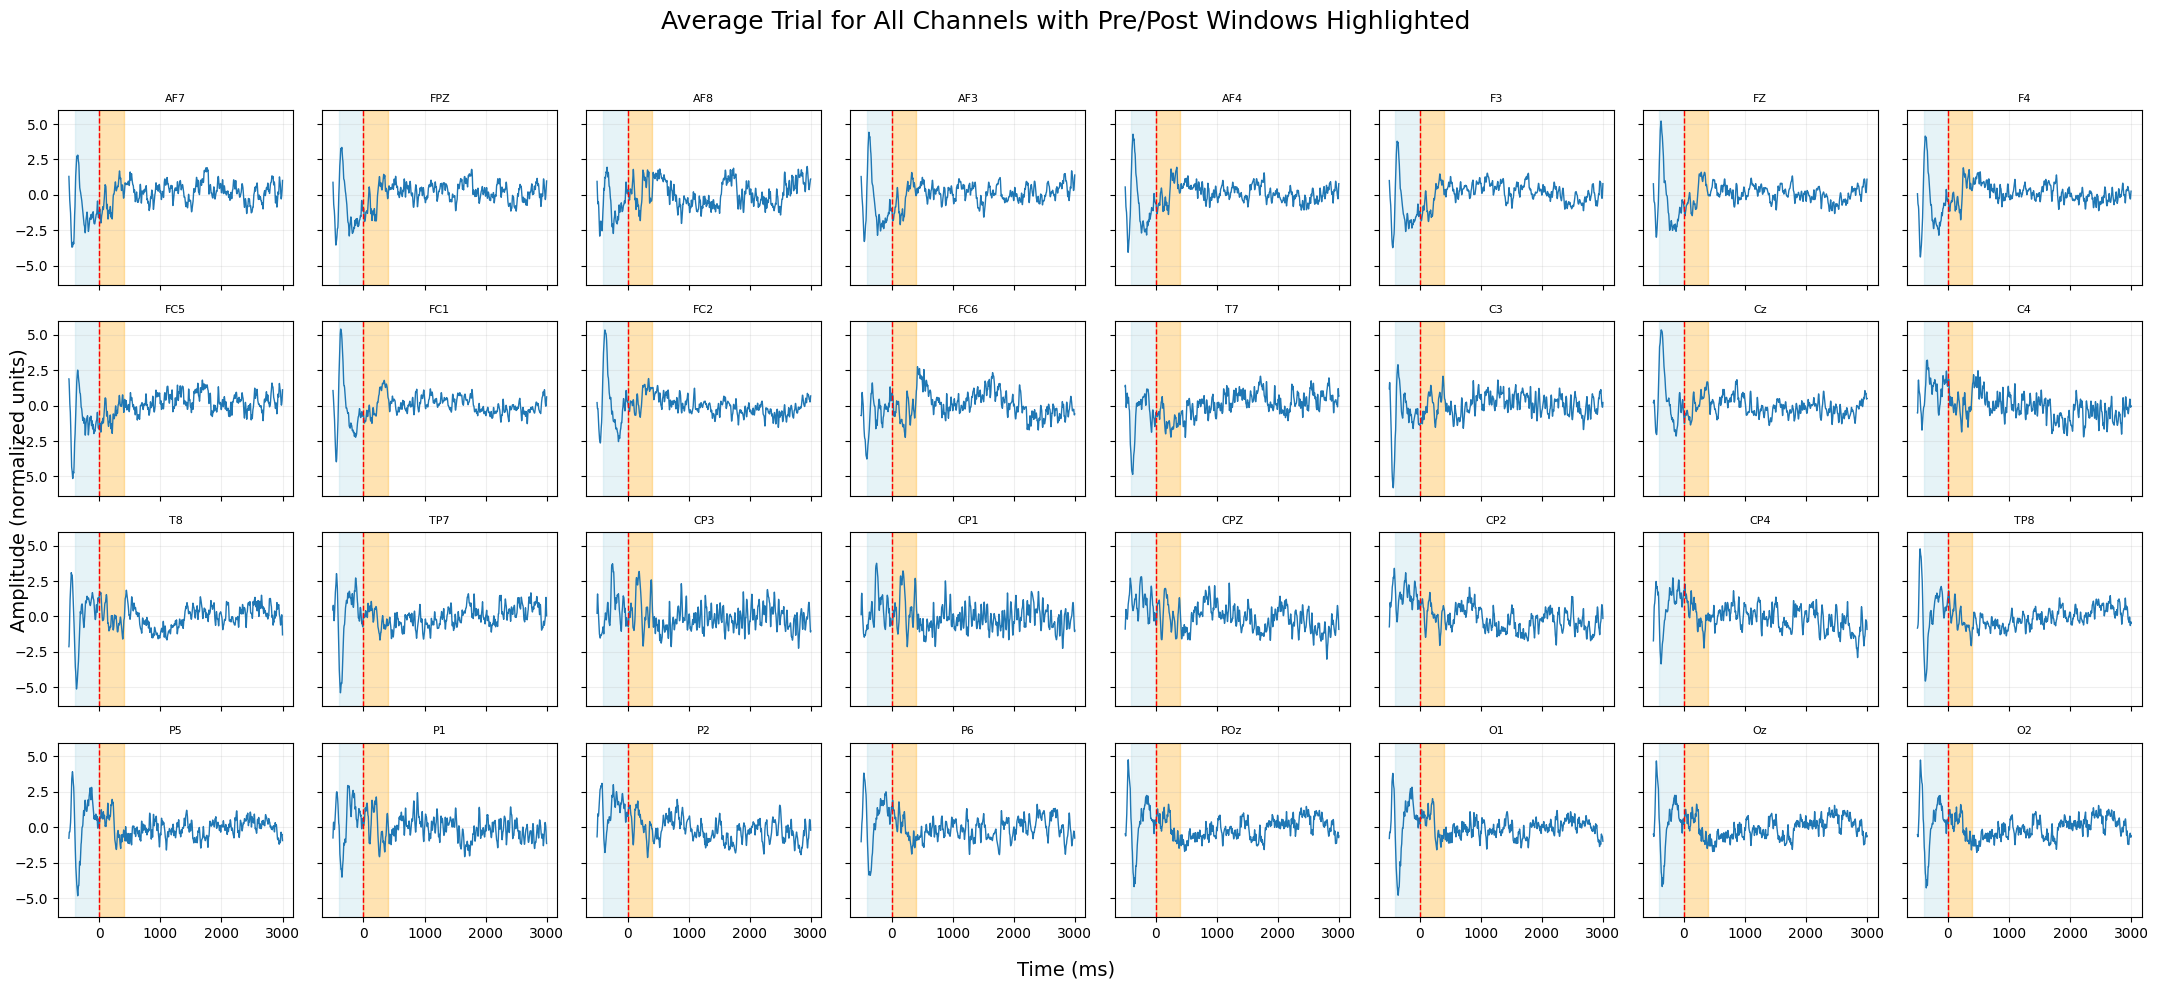

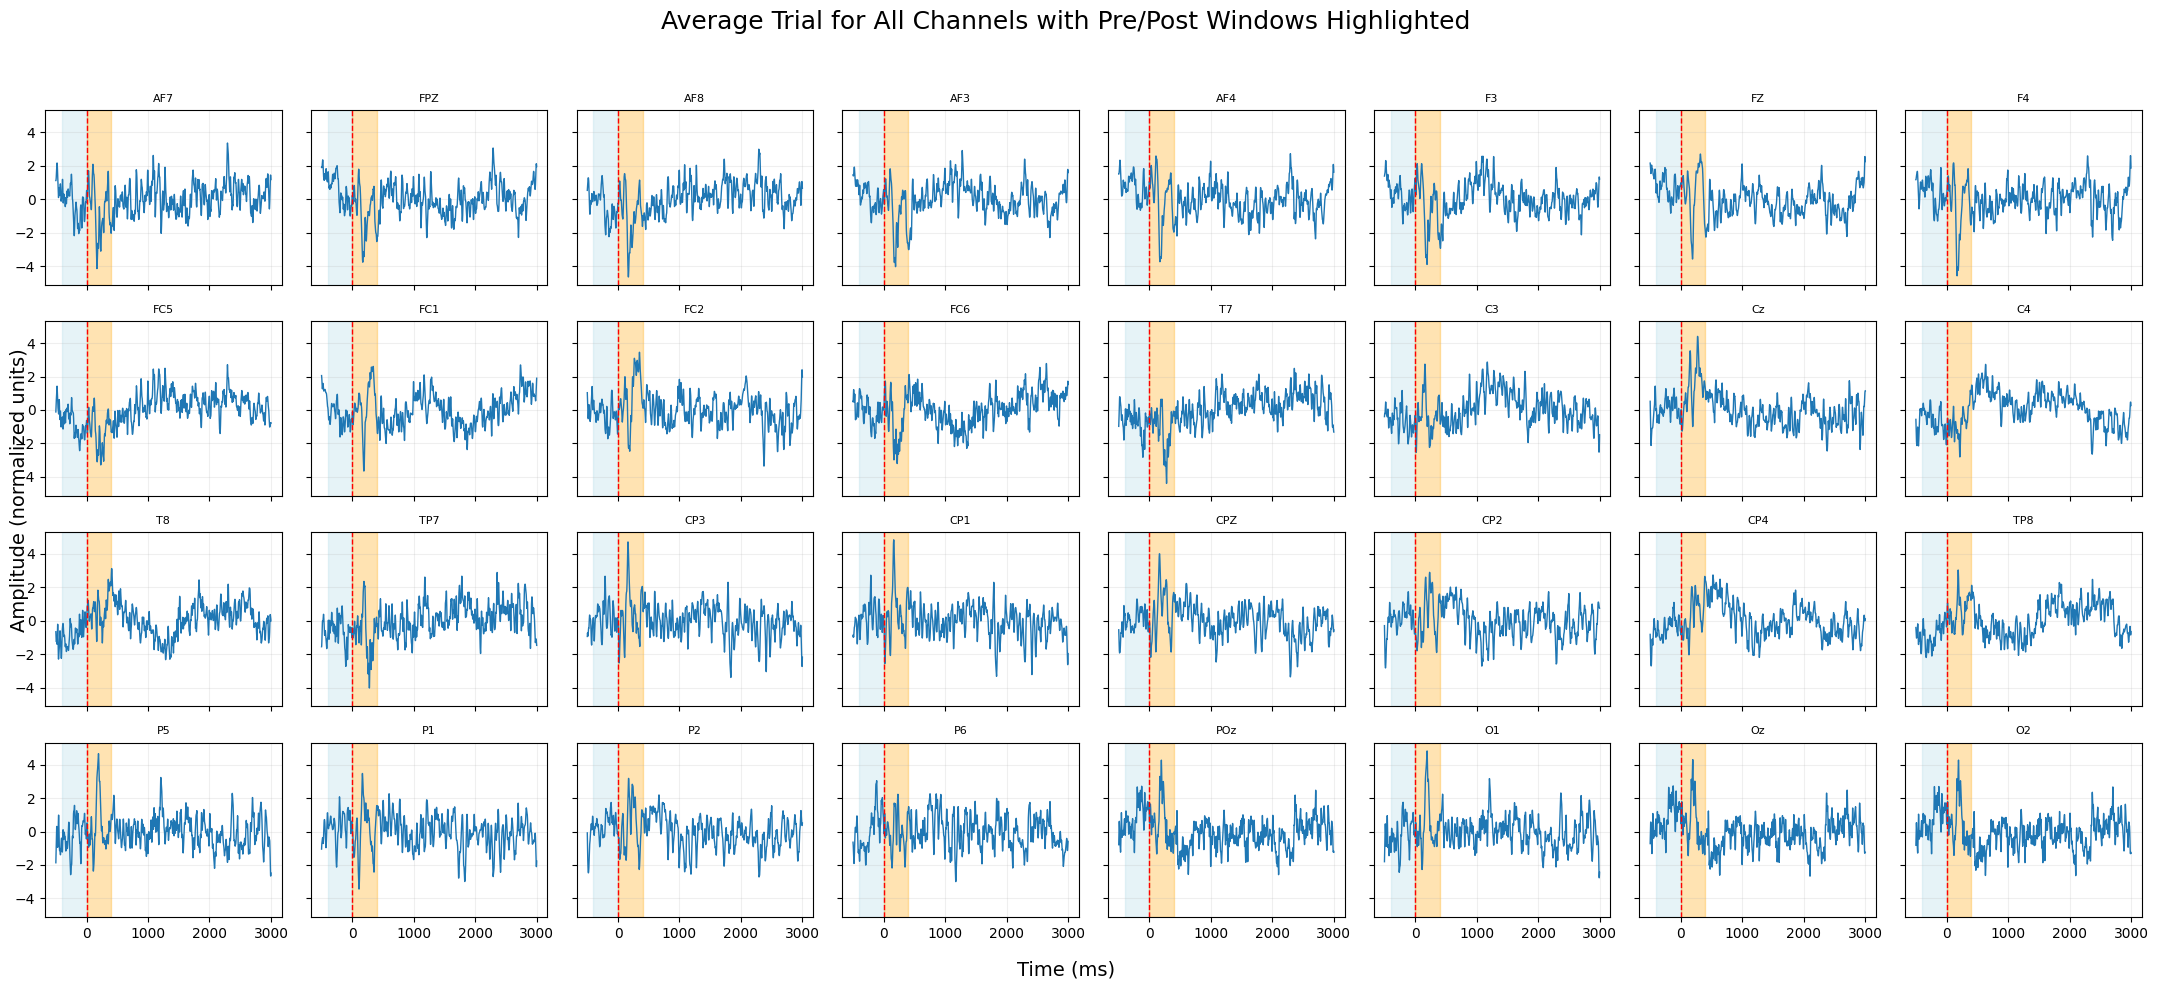

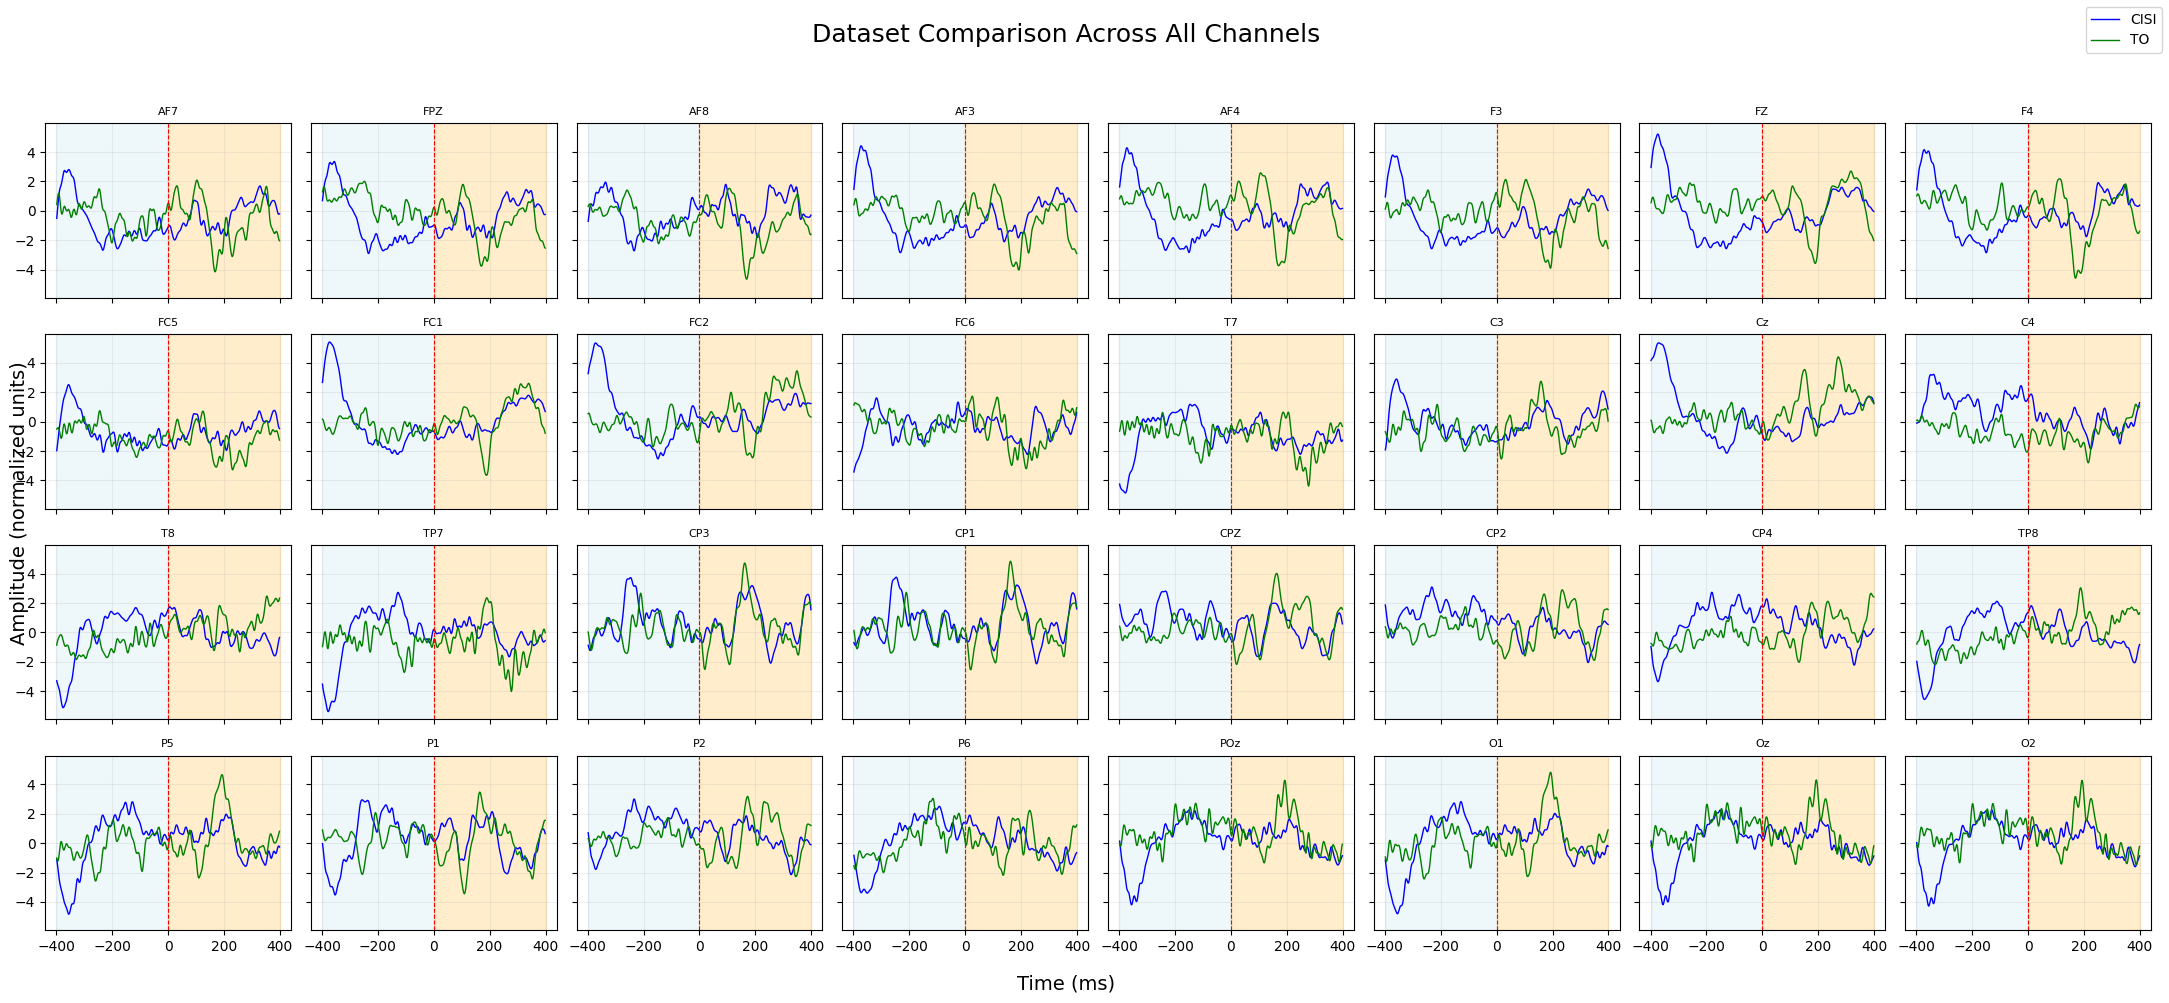

In [40]:
plot_all_channels_with_windows(cisi_tactile_epochs_avg, cisi_epochs.ch_names)
plot_all_channels_with_windows(to_tactile_epochs_avg, to_epochs.ch_names)

plot_overlay_all_channels(
    dataA=cisi_tactile_epochs_avg,           # e.g., subject A
    dataB=to_tactile_epochs_avg,     # e.g., subject B OR condition B
    ch_names=cisi_epochs.ch_names,
    labelA="CISI",
    labelB="TO"
)

In [31]:
def ms_to_idx(ms, sfreq=512, t_start_ms=-500):
    """Convert a time in ms to an index relative to the data array."""
    return int((ms - t_start_ms) * sfreq / 1000)

# Compute index boundaries
idx_pre_start  = ms_to_idx(-400)
idx_pre_end    = ms_to_idx(0)

idx_post_start = ms_to_idx(0)
idx_post_end   = ms_to_idx(400)

print(idx_pre_start, idx_pre_end)
print(idx_post_start, idx_post_end)

cisi_pre = cisi_tactile_epochs_avg[:, idx_pre_start:idx_pre_end]
cisi_post = cisi_tactile_epochs_avg[:, idx_post_start:idx_post_end]

to_pre = to_tactile_epochs_avg[:, idx_pre_start:idx_pre_end]
to_post = to_tactile_epochs_avg[:, idx_post_start:idx_post_end]

print(cisi_pre.shape)
print(cisi_post.shape)

51 256
256 460
(32, 205)
(32, 204)


In [32]:
# Run channel by channel analysis with fixed lag and window size
import numpy as np
from sklearn.metrics import mutual_info_score
import matplotlib.pyplot as plt

def mutual_info(x, y, n_bins=20):
    """Compute MI between two continuous 1D arrays via histogram binning."""
    # Digitize into bins
    x_binned = np.digitize(x, np.histogram_bin_edges(x, bins=n_bins))  
    y_binned = np.digitize(y, np.histogram_bin_edges(y, bins=n_bins))
    return mutual_info_score(x_binned, y_binned)

def compute_mi_matrix(data, n_bins=20):
    """
    data: shape (channels, timepoints)
    returns: MI matrix shape (channels, channels)
    """
    n_channels = data.shape[0]
    mi_mat = np.zeros((n_channels, n_channels))
    
    for i in range(n_channels):
        for j in range(n_channels):
            mi_mat[i, j] = mutual_info(data[i], data[j], n_bins=n_bins)
    
    return mi_mat

cisi_mi_pre  = compute_mi_matrix(cisi_pre)
cisi_mi_post = compute_mi_matrix(cisi_post)

to_mi_pre = compute_mi_matrix(to_pre)
to_mi_post = compute_mi_matrix(to_post)

print("MI pre shape :", cisi_mi_pre.shape)   # (32, 32)
print("MI post shape:", cisi_mi_post.shape)  # (32, 32)

def plot_mi_heatmap(mi_mat, title, ch_names=None):
    mask = np.triu(np.ones_like(mi_mat, dtype=bool), k=1)

    tri_mat = np.where(mask, mi_mat, np.nan)

    plt.figure(figsize=(8, 6))
    plt.imshow(tri_mat, origin='lower', aspect='auto')
    plt.colorbar(label="Mutual Information")
    plt.title(title)

    if ch_names is not None:
        plt.xticks(range(len(ch_names)), ch_names, rotation=90)
        plt.yticks(range(len(ch_names)), ch_names)

    plt.tight_layout()
    plt.show()


MI pre shape : (32, 32)
MI post shape: (32, 32)


In [33]:
import matplotlib.pyplot as plt
import numpy as np

def plot_heatmap_grid(
    mats, 
    titles, 
    ch_names=None, 
    triangular=False,
    overall_title=None
):
    """
    mats: list of 4 MI matrices
    titles: list of 4 subplot titles
    ch_names: list of channel names
    triangular: if True, apply upper-triangular mask (no diagonal)
    overall_title: str, optional (e.g. "Subject 5")
    """
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.ravel()

    for i, ax in enumerate(axes):
        mi = mats[i]

        # Triangular masking (upper triangle without diagonal)
        if triangular:
            mask = np.triu(np.ones_like(mi, dtype=bool), k=1)
            mi_to_plot = np.where(mask, mi, np.nan)
        else:
            mi_to_plot = mi

        im = ax.imshow(mi_to_plot, origin='lower', aspect='auto')
        ax.set_title(titles[i])

        # Optional channel labels
        if ch_names is not None:
            ax.set_xticks(range(len(ch_names)))
            ax.set_yticks(range(len(ch_names)))
            ax.set_xticklabels(ch_names, rotation=90)
            ax.set_yticklabels(ch_names)

        # Individual colorbar
        fig.colorbar(im, ax=ax, fraction=0.046)

    # Add the overall figure title
    if overall_title is not None:
        fig.suptitle(overall_title, fontsize=16, y=0.98)

    plt.tight_layout(rect=[0, 0, 1, 0.96])  # Leave space for main title
    plt.show()



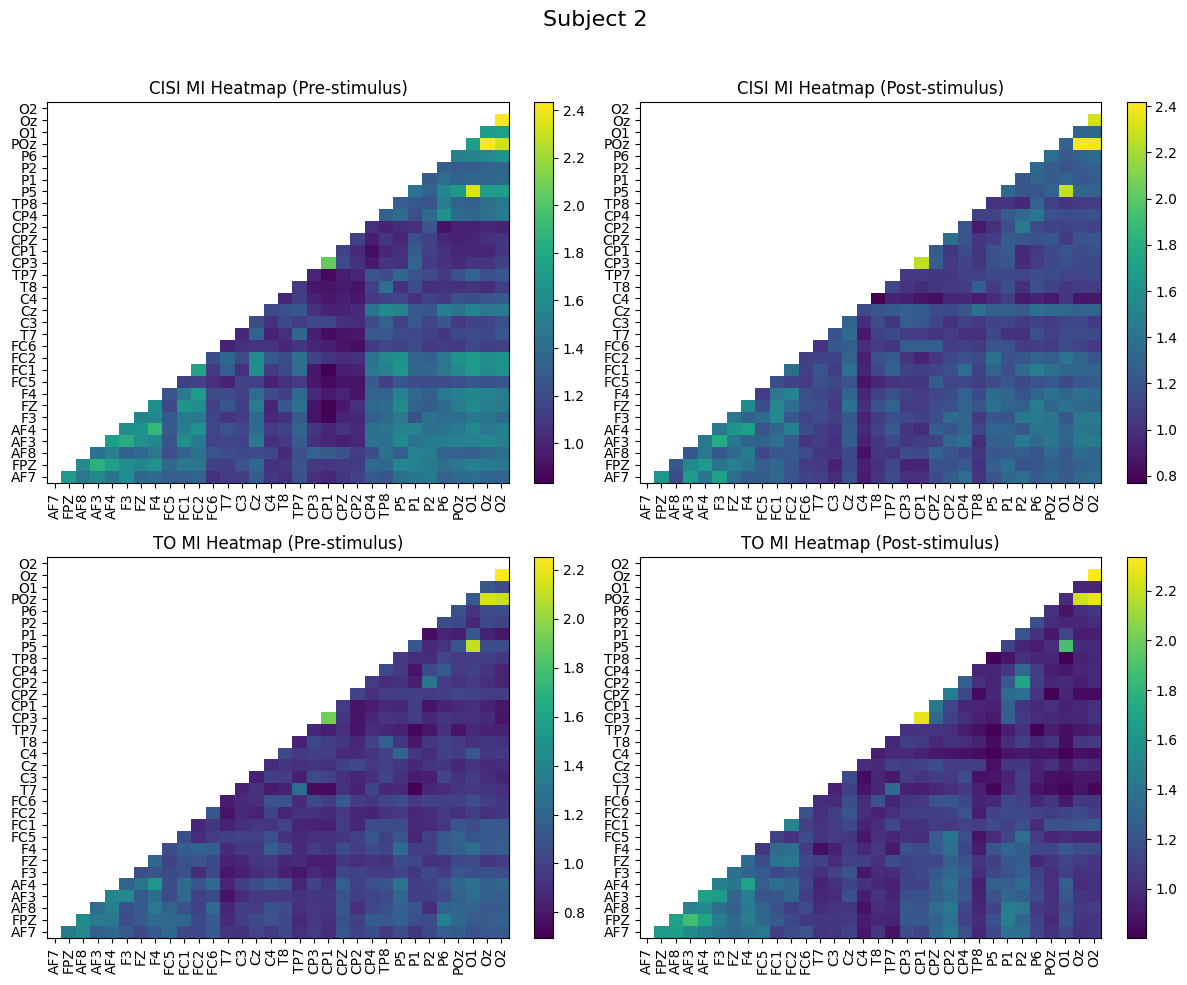

In [34]:
mats = [cisi_mi_pre, cisi_mi_post, to_mi_pre, to_mi_post]
titles = [
    "CISI MI Heatmap (Pre-stimulus)",
    "CISI MI Heatmap (Post-stimulus)",
    "TO MI Heatmap (Pre-stimulus)",
    "TO MI Heatmap (Post-stimulus)"
]

plot_heatmap_grid(
    mats, 
    titles, 
    ch_names=cisi_epochs.ch_names, 
    triangular=True, 
    overall_title = f"Subject {SUBJECT_NUM}"
)


In [29]:
# Repeat heatmap but with NeuralMI
def compute_neuralmi_matrix(data, window_size, lag):
    n_channels = data.shape[0]
    mi_mat = np.zeros((n_channels, n_channels))

    processor_params = {'window_size': window_size}

    base_params = {
            'embedding_dim': 16,
            'hidden_dim': 32,
            'n_layers': 2,
            'learning_rate': 1e-3,
            'batch_size': 128,
            'n_epochs': 500,
            'patience': 30,
        }

    for i in range (n_channels):
        for j in range(i + 1, n_channels):
            # print(data[i].reshape(1, -1).shape)
            print(data[i].reshape(-1,1).shape)
            mi_val = nmi.run(
                x_data=data[i].reshape(1, -1),
                y_data=data[j].reshape(1, -1), 
                mode='estimate', 
                processor_type='continuous',
                processor_params=processor_params, 
                base_params=base_params,
                n_workers=1
            )
            mi_mat[i, j] = mi_val.mi_estimate

In [30]:
cisi_mi_pre_nmi = compute_neuralmi_matrix(cisi_pre, window_size=cisi_pre.shape[1], lag=0)
cisi_mi_post_nmi = compute_neuralmi_matrix(cisi_post, window_size=cisi_post.shape[1], lag=0)
to_mi_pre_nmi = compute_neuralmi_matrix(to_pre, window_size=to_pre.shape[1], lag=0)
to_mi_post_nmi = compute_neuralmi_matrix(to_post, window_size=to_post.shape[1], lag=0)

mats = [cisi_mi_pre_nmi, cisi_mi_post_nmi, to_mi_pre_nmi, to_mi_post_nmi]
titles = [
    "CISI MI Heatmap (Pre-stimulus)",
    "CISI MI Heatmap (Post-stimulus)",
    "TO MI Heatmap (Pre-stimulus)",
    "TO MI Heatmap (Post-stimulus)"
]

plot_heatmap_grid(
    mats, 
    titles, 
    ch_names=cisi_epochs.ch_names, 
    triangular=True, 
    overall_title = f"Subject {SUBJECT_NUM} with NeuralMI"
)

(205, 1)
2025-11-20 10:06:25 - neural_mi - WARNING - `processor_type` is deprecated. Use `processor_type_x` and `processor_type_y` instead.
2025-11-20 10:06:25 - neural_mi - WARNING - `processor_params` is deprecated. Use `processor_params_x` and `processor_params_y` instead.
2025-11-20 10:06:25 - neural_mi - INFO - Starting parameter sweep sequentially (n_workers=1)...


Sequential Sweep Progress:   0%|          | 0/1 [00:00<?, ?it/s]

2025-11-20 10:06:25 - neural_mi - WARNING - batch_size (128) > n_train_samples (1). Reducing to 1.


Run 825ee48d-39d5-4464-bb81-2ee200c7a21e_c0:   0%|          | 0/500 [00:00<?, ?it/s]

TrainingError: Training failed to produce a valid model checkpoint.